# 01. 패션 상품 이미지 기반 의류 유형 분류

## 프로젝트 개요
| 항목 | 내용 |
|---|---|
| 과제 | 상품 이미지 기반 의류 카테고리 5종 분류 (원피스 / 재킷 / 바지 / 스커트 / 상의) |
| 데이터 | Fashion200K (Han et al., ICCV 2017) 기반 정제 데이터, 12,842장 |
| 비교 실험 | ResNet18 Scratch vs ImageNet Pretrained (Feature Extraction / Fine-tuning) |
| 평가 지표 | Macro F1, Accuracy, 클래스별 Recall, Precision, 혼동행렬 |

## 데이터셋 구성

`fashion_dataset/` 폴더는 이미지 폴더(`images/`)와 메타데이터 CSV 3개로 구성됨.

| 파일 | 행 단위 | 내용 | 용도 |
|---|---|---|---|
| `class_mapping.csv` | 클래스 1개 (5행) | `target_id` ↔ 영문 클래스명 ↔ 한글명 대응 | 라벨 번호 해석 |
| `class_counts.csv` | 클래스 × 분할 (15행) | 이미지 수, 상품 수, 계획 이미지 수, 보존 비율 | 분포 요약 확인 |
| `metadata.csv` | 이미지 1장 (12,842행) | 경로, 분할, 정답 라벨, 상품 정보, 크기 등 | 학습·분석의 기준 데이터 |

## 1. 데이터 로드

In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_ROOT = Path("fashion_dataset")  
META_PATH = DATA_ROOT / "metadata.csv"
MAP_PATH = DATA_ROOT / "class_mapping.csv"
COUNTS_PATH = DATA_ROOT / "class_counts.csv"

SPLITS = ["train", "val", "test"]

meta = pd.read_csv(META_PATH, encoding="utf-8-sig")
class_map = pd.read_csv(MAP_PATH, encoding="utf-8-sig")
class_counts = pd.read_csv(COUNTS_PATH, encoding="utf-8-sig") 

print("metadata shape:", meta.shape)
display(class_map)
display(meta.head())

metadata shape: (12842, 15)


,target_id,category,class_name_ko
0,0,dress,원피스
1,1,jacket,재킷
2,2,pants,바지
3,3,skirt,스커트
4,4,top,상의


,image_id,image_path,split,target_id,category,class_name_ko,subcategory,product_id,group_id,original_split,width,height,file_size_bytes,image_source,crop_applied
0,fashion_00001e0704cfd182164c129d,images/train/fashion_00001e0704cfd182164c129d.jpg,train,1,jacket,재킷,casual_jackets,90618778,product_90618778,train,194,384,20241,url,1
1,fashion_00046ef7d53aeb9ed03857bf,images/train/fashion_00046ef7d53aeb9ed03857bf.jpg,train,2,pants,바지,leggings,91162030,product_91162030,train,173,377,22636,url,1
2,fashion_0005153a36b16117fef45fd7,images/test/fashion_0005153a36b16117fef45fd7.jpg,test,2,pants,바지,wide-leg_and_palazzo_pants,90660442,product_90660442,test,153,384,13873,url,1
3,fashion_0007f531399d6e406c90c152,images/train/fashion_0007f531399d6e406c90c152.jpg,train,3,skirt,스커트,knee_length_skirts,91400146,product_91400146,train,250,267,11487,url,1
4,fashion_000c5dea07701786b1a653b9,images/train/fashion_000c5dea07701786b1a653b9.jpg,train,1,jacket,재킷,waistcoats_and_gilets,71639376,product_71639376,train,323,364,26948,url,1


### 클래스 정의

| target_id | category | 한글명 |
|---|---|---|
| 0 | dress | 원피스 |
| 1 | jacket | 재킷 |
| 2 | pants | 바지 |
| 3 | skirt | 스커트 |
| 4 | top | 상의 |

### `metadata.csv` 컬럼 구성 (15개)

| 역할 | 컬럼 |
|---|---|
| 이미지 식별·위치 | `image_id`, `image_path` |
| 분할 | `split`, `original_split` |
| 정답 라벨 | `target_id` (학습용 숫자), `category`, `class_name_ko` |
| 상품 정보 | `subcategory`, `product_id`, `group_id` |
| 이미지 속성 | `width`, `height`, `file_size_bytes` |
| 수집·가공 정보 | `image_source`, `crop_applied` |

> 모델 입력은 이미지만 사용하며, 정답 라벨 외 컬럼(카테고리·하위분류·상품 ID·경로 등)은 분석 용도로만 활용함.

## 2. CSV 데이터 확인 (metadata.csv)
1. 결측치와 중복 확인
    - 결측치는 컬럼별로, 중복은 행 전체와 고유해야 하는 컬럼(`image_id`, `image_path`) 기준으로 확인

In [5]:
print("=== 결측치 ===")
print(meta.isna().sum())

print("\n=== 중복 ===")
print("완전 중복 행:", meta.duplicated().sum())
print("image_id 중복:", meta["image_id"].duplicated().sum())
print("image_path 중복:", meta["image_path"].duplicated().sum())

=== 결측치 ===
image_id           0
image_path         0
split              0
target_id          0
category           0
class_name_ko      0
subcategory        0
product_id         0
group_id           0
original_split     0
width              0
height             0
file_size_bytes    0
image_source       0
crop_applied       0
dtype: int64

=== 중복 ===
완전 중복 행: 0
image_id 중복: 0
image_path 중복: 0


2. 라벨 표기 검증
    - `target_id`, `category`, `class_name_ko` 조합을 기준표(`class_mapping.csv`)와 비교하여 오타·불일치 확인
    - 눈에 보이지 않는 앞뒤 공백 포함 여부 확인
    - 동일 상품(`product_id`)이 여러 클래스로 라벨링된 경우가 있는지 확인

In [6]:
label_cols = ["target_id", "category", "class_name_ko"]

# 1) metadata에 실제로 등장하는 라벨 조합
combos = meta[label_cols].drop_duplicates().sort_values("target_id")
display(combos)

# 2) class_mapping(기준표)과 비교: 양쪽에 다 있어야 정상
check = combos.merge(class_map, on=label_cols, how="outer", indicator=True)
print(check["_merge"].value_counts())   # left_only = metadata에만 있는 조합 → 오타 의심

# 3) 앞뒤 공백 확인 (눈으로 안 보이는 오타)
for c in ["category", "class_name_ko"]:
    print(f"{c} 공백 포함:", (meta[c] != meta[c].str.strip()).sum())

,target_id,category,class_name_ko
9,0,dress,원피스
0,1,jacket,재킷
1,2,pants,바지
3,3,skirt,스커트
6,4,top,상의


_merge
both          5
left_only     0
right_only    0
Name: count, dtype: int64
category 공백 포함: 0
class_name_ko 공백 포함: 0


3. 경로와 분할 일치 확인
    - `image_path`의 폴더명(`images/{split}/`)이 `split` 값과 일치하는지 확인
    - 파일명이 `image_id`와 일치하는지, 확장자가 통일되어 있는지 확인

In [7]:
path_parts = meta["image_path"].str.split("/")
path_folder = path_parts.str[1]                              # train / val / test
file_stem = path_parts.str[-1].str.replace(".jpg", "", regex=False)

print("경로 폴더 ≠ split:", (path_folder != meta["split"]).sum())
print("파일명 ≠ image_id:", (file_stem != meta["image_id"]).sum())
print("확장자 종류:", meta["image_path"].str[-4:].unique())

경로 폴더 ≠ split: 0
파일명 ≠ image_id: 0
확장자 종류: <StringArray>
['.jpg']
Length: 1, dtype: str


4. `product_id`와 `group_id` 관계 확인
    - `group_id`가 `"product_" + product_id` 형태로 상품과 1:1 대응하는지 확인
    - 동일 정보일 경우 `group_id`는 분석에서 제외하고 `product_id`를 상품 단위 기준으로 사용

In [8]:
same = (meta["group_id"] == "product_" + meta["product_id"].astype(str))
print("group_id == 'product_' + product_id :", same.all())
print("고유 개수 → product_id:", meta["product_id"].nunique(),
      "/ group_id:", meta["group_id"].nunique())

group_id == 'product_' + product_id : True
고유 개수 → product_id: 7495 / group_id: 7495


5. `split`과 `original_split` 비교
    - 두 값이 다른 행이 있는지, 있다면 어떤 방향으로 이동했는지 교차표로 확인

In [10]:
display(pd.crosstab(meta["original_split"], meta["split"]))

split,test,train,val
original_split,,,
test,2597,0,0
train,0,8523,1722


- original_split / split 차이점
- original_split 상에는 test/train 데이터만 존재
- split 속성에는 test/validation/train 데이터 존재
- train 데이터에서 -> train/validation 분할한 것 
- 따라서 추후 original_split은 필요하지 x

6. 수집·가공 정보 확인
    - `crop_applied`가 모두 1(crop 완료)인지 확인
    - `image_source` 값 분포 확인

In [11]:
print(meta["crop_applied"].value_counts())
print(meta["image_source"].value_counts())

crop_applied
1    12842
Name: count, dtype: int64
image_source
url    12842
Name: count, dtype: int64


### metadata 점검 결과
| 항목 | 결과 | 판단 |
|---|---|---|
| 결측치 / 중복 | 결측 0, 완전 중복 행 0, `image_id`·`image_path` 중복 0 | 정제 불필요 |
| 라벨 표기 | 라벨 조합 5개 모두 기준표와 일치, 공백 0, 복수 클래스 상품 0 | 표기 오류 없음 |
| 경로–분할 | 폴더명 불일치 0, 파일명 불일치 0, 확장자 `.jpg` 통일 | 경로 정보 신뢰 가능 |
| `product_id`–`group_id` | 7,495개로 완전히 1:1 대응 | `group_id` 제외, `product_id`만 사용 |
| `split`–`original_split` | Val 1,722장이 원본 Train에서 분리됨, Test는 원본 그대로 | 의도된 차이, 오분류 아님 |
| 수집·가공 정보 | `crop_applied` 전부 1, `image_source` 전부 `url` | 전 이미지 crop 완료 → 추가 crop 시 정보 손실 주의 |

## 3. 이미지 경로 연결
1. 경로 연결 및 누락 파일 확인
    - `DATA_ROOT / image_path`로 전체 경로를 생성하고 실제 파일 존재 여부 확인

In [14]:
meta['full_path'] = meta['image_path'].apply(lambda p: DATA_ROOT/p)
meta['exists'] = meta['full_path'].apply(lambda p: p.exists())

print('누락 파일:', (~meta['exists']).sum(),'/',len(meta))
display(meta.groupby("split")["exists"].agg(["sum", "size"]).loc[SPLITS])

누락 파일: 0 / 12842


,sum,size
split,,
train,8523,8523
val,1722,1722
test,2597,2597


2. 등록되지 않은 파일 확인
    - 분할 폴더 내 파일 중 `metadata.csv`에 없는 파일이 있는지 확인 (CSV ↔ 폴더 양방향 검증)

In [15]:
csv_paths = set(meta["image_path"])

for s in SPLITS:
    folder_files = {f"images/{s}/{f.name}" for f in (DATA_ROOT / "images" / s).iterdir() if f.is_file()}
    extra = folder_files - csv_paths
    print(f"[{s:5s}] 폴더 파일 {len(folder_files):5d}개 | CSV에 없는 파일 {len(extra)}개")
    if extra:
        print("   예시:", list(extra)[:3])

[train] 폴더 파일  8524개 | CSV에 없는 파일 1개
   예시: ['images/train/fashion_sample.zip']
[val  ] 폴더 파일  1722개 | CSV에 없는 파일 0개
[test ] 폴더 파일  2597개 | CSV에 없는 파일 0개


### 3-1. 비등록 파일 점검: `fashion_sample.zip`
- 등록되지 않은 파일 확인 결과, `images/train/` 폴더에서 CSV에 없는 파일 1개 발견
    - `fashion_sample.zip` (이미지가 아닌 압축 파일, 내부에 다수의 파일 포함)
- 학습은 CSV 경로 기준으로 로드하므로 직접적인 영향은 없으나, 내부 데이터가 **기존 이미지의 중복**인지 **누락된 신규 데이터**인지 판단 필요

**점검 방법**
1. 기존 이미지 12,842장의 MD5 해시 계산
2. 압축을 해제하지 않고 zip 내부 파일을 직접 읽어 비교
    - 파일명 일치 여부: 같은 이름의 파일이 기존에 있는가
    - 내용 일치 여부(MD5): 이름과 관계없이 같은 이미지가 기존에 있는가
    - 일치 시 해당 이미지의 분할(train / val / test) 확인

**판단 기준**
- 전부 내용 일치 → 기존 이미지의 복사본으로 판단, 직접적 영향은 없기에 무시
- 불일치 파일 존재 → 신규 데이터 여부를 추가 확인

In [16]:
import hashlib
import zipfile
from tqdm.auto import tqdm

def md5_bytes(b):
    return hashlib.md5(b).hexdigest()

meta["md5"] = [md5_bytes(p.read_bytes()) for p in tqdm(meta["full_path"], desc="기존 이미지 해시")]
md5_to_split = meta.groupby("md5")["split"].first()   # 해시 → 어느 분할 이미지인지
known_names = set(meta["full_path"].apply(lambda p: p.name))

c:\cv_project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
기존 이미지 해시: 100%|██████████| 12842/12842 [00:43<00:00, 295.82it/s]


In [17]:
ZIP_FILE = DATA_ROOT / "images/train/fashion_sample.zip"

rows = []
with zipfile.ZipFile(ZIP_FILE) as z:
    for info in z.infolist():
        if info.is_dir():
            continue
        name = Path(info.filename).name
        h = md5_bytes(z.read(info))
        rows.append({
            "zip_path": info.filename,
            "name_match": name in known_names,       # 같은 파일명이 기존에 있는가
            "content_match": h in md5_to_split.index, # 같은 내용이 기존에 있는가
            "matched_split": md5_to_split.get(h),     # 있다면 어느 분할의 이미지와 같은가
        })

zip_df = pd.DataFrame(rows)
print("zip 내부 파일 수:", len(zip_df))
print("확장자:", zip_df["zip_path"].str.extract(r"(\.[^.]+)$")[0].value_counts().to_dict())
display(pd.crosstab(zip_df["name_match"], zip_df["content_match"]))
print("\n내용이 일치하는 기존 이미지의 분할:")
print(zip_df["matched_split"].value_counts(dropna=False))

zip 내부 파일 수: 352
확장자: {'.jpg': 352}


content_match,True
name_match,
True,352



내용이 일치하는 기존 이미지의 분할:
matched_split
train    352
Name: count, dtype: int64


### 이미지 연결 점검 결과
| 항목 | 결과 | 판단 |
|---|---|---|
| 누락 파일 | 0 / 12,842 | CSV의 모든 경로가 실제 파일과 연결됨 |
| 등록되지 않은 파일 | train 1개 (`fashion_sample.zip`), val 0, test 0 | 이미지 기준으로는 CSV와 폴더가 완전 일치 |
| 열리지 않는 파일 | 0 | 손상 파일 없음 |
| CSV 크기 불일치 | 0 | 실제 이미지 크기와 CSV의 `width`, `height` 일치 |

#### `fashion_sample.zip` 점검 결과
| 항목 | 결과 |
|---|---|
| zip 내부 파일 수 | 352개 (전부 `.jpg`) |
| 파일명·내용(MD5) 모두 일치 | 352 / 352 |
| 일치 이미지의 분할 | train 352, val 0, test 0 |

- 판단: zip 내부 파일은 모두 기존 train 이미지의 완전 복사본으로, 새로운 데이터나 다른 분할의 이미지는 없음
- 처리: 원본 재현성을 위해 파일은 그대로 두고, 데이터 로드는 항상 CSV 경로 기준으로 수행하여 학습에서 제외
- MD5는 바이트 단위 완전 일치만 판별하므로, 밝기·크기 등이 변형된 근접 중복은 별도 점검 대상으로 남김

## 4. 이미지 데이터 확인
1. 클래스별 이미지 수 및 비율
    - 분할별 클래스 분포 표와 그래프, 
    - `class_counts.csv`와 교차 검증

In [18]:
order = class_map.sort_values("target_id")["category"].tolist()   # 클래스 순서를 target_id 기준으로 고정

img_counts = (pd.crosstab(meta["category"], meta["split"])
                .reindex(index=order, columns=SPLITS))
img_ratio = (pd.crosstab(meta["category"], meta["split"], normalize="columns")
               .reindex(index=order, columns=SPLITS) * 100).round(2)

print("=== 분할별 이미지 수 ===")
display(img_counts.assign(total=img_counts.sum(axis=1)))   # 클래스별 합계 열 추가
print("분할별 합계:", img_counts.sum().to_dict())

print("\n=== 분할별 클래스 비율(%) ===")
display(img_ratio)

# 불균형 정도: 가장 많은 클래스 수 / 가장 적은 클래스 수
for s in SPLITS:
    c = img_counts[s]
    print(f"[{s:5s}] 최대/최소 = {c.max() / c.min():.3f} ({c.idxmax()} {c.max()} / {c.idxmin()} {c.min()})")

=== 분할별 이미지 수 ===


split,train,val,test,total
category,,,,
dress,1736,346,533,2615
jacket,1615,331,502,2448
pants,1670,340,503,2513
skirt,1834,362,558,2754
top,1668,343,501,2512


분할별 합계: {'train': 8523, 'val': 1722, 'test': 2597}

=== 분할별 클래스 비율(%) ===


split,train,val,test
category,,,
dress,20.37,20.09,20.52
jacket,18.95,19.22,19.33
pants,19.59,19.74,19.37
skirt,21.52,21.02,21.49
top,19.57,19.92,19.29


[train] 최대/최소 = 1.136 (skirt 1834 / jacket 1615)
[val  ] 최대/최소 = 1.094 (skirt 362 / jacket 331)
[test ] 최대/최소 = 1.114 (skirt 558 / top 501)


In [19]:
# clas_counts.csv와 교차 검증
from_meta = (meta.groupby(["category", "split"])
                 .agg(meta_images=("image_id", "size"),
                      meta_products=("product_id", "nunique"))
                 .reset_index())

check = class_counts.merge(from_meta, on=["category", "split"])
check["images_match"] = check["images"] == check["meta_images"]
check["products_match"] = check["products"] == check["meta_products"]

display(check[["category", "split", "images", "meta_images", "products", "meta_products",
               "images_match", "products_match"]])
print("모두 일치:", check["images_match"].all() and check["products_match"].all())

,category,split,images,meta_images,products,meta_products,images_match,products_match
0,dress,train,1736,1736,1000,1000,True,True
1,dress,val,346,346,200,200,True,True
2,dress,test,533,533,300,300,True,True
3,jacket,train,1615,1615,998,998,True,True
4,jacket,val,331,331,200,200,True,True
5,jacket,test,502,502,299,299,True,True
6,pants,train,1670,1670,999,999,True,True
7,pants,val,340,340,200,200,True,True
8,pants,test,503,503,300,300,True,True
9,skirt,train,1834,1834,999,999,True,True


모두 일치: True


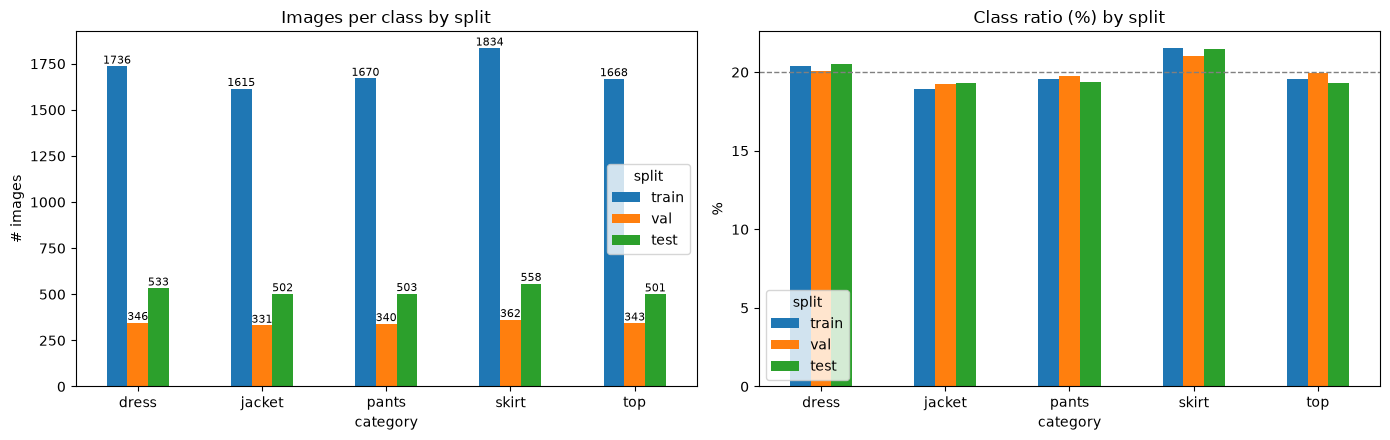

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

img_counts.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Images per class by split")
axes[0].set_ylabel("# images")
for cont in axes[0].containers:
    axes[0].bar_label(cont, fontsize=8)

img_ratio.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Class ratio (%) by split")
axes[1].set_ylabel("%")
axes[1].axhline(20, ls="--", c="gray", lw=1)

plt.tight_layout()
plt.show()

## 4. 상품(product) 단위 분포

같은 상품의 여러 사진은 같은 분할에 들어갑니다.
이미지 수만 보면 상품 다양성을 놓칠 수 있으므로 **상품 수**와 **상품당 이미지 수**도 확인합니다.

In [6]:
prod_counts = (meta.groupby(["category", "split"])["product_id"].nunique()
                   .unstack().reindex(index=order, columns=SPLITS))
print("=== 분할별 상품 수 ===")
display(prod_counts)

imgs_per_prod = meta.groupby(["split", "product_id"]).size()
print("=== 상품당 이미지 수 ===")
display(imgs_per_prod.groupby(level="split").describe()[["mean", "min", "max"]])

=== 분할별 상품 수 ===


split,train,val,test
category,,,
dress,1000,200,300
jacket,998,200,299
pants,999,200,300
skirt,999,200,300
top,1000,200,300


=== 상품당 이미지 수 ===


,mean,min,max
split,,,
test,1.732488,1.0,2.0
train,1.705965,1.0,2.0
val,1.722000,1.0,2.0


### 결과
- 클래스별 상품 수: Train ≈ 1,000 / Val 200 / Test 300 (클래스 간 동일)
- 상품당 이미지 1 ~ 2장 (평균 약 1.7장)

### 판단
- 학습 데이터 축소 실험 시 이미지 단위가 아닌 **상품 단위 샘플링**을 적용하여, 동일 상품의 이미지가 분리되지 않도록 함

## 5. 분할 간 데이터 누수 점검

같은 상품이나 그룹이 Train과 Val/Test에 동시에 있으면, 모델이 **본 적 있는 상품**을 맞히는 셈이 되어 성능이 과대평가됩니다.

In [ ]:
for col in ["product_id", "group_id", "image_id"]:
    n_split = meta.groupby(col)["split"].nunique()
    leaked = n_split[n_split > 1]
    print(f"{col:10s}: 여러 분할에 걸친 값 {len(leaked)}개")

product_id: 여러 분할에 걸친 값 0개
group_id  : 여러 분할에 걸친 값 0개
image_id  : 여러 분할에 걸친 값 0개


### 결과
| 기준 | 복수 분할에 걸친 값 |
|---|---|
| product_id | 0 |
| group_id | 0 |
| image_id | 0 |

### 한계 및 후속 계획
- ID 기준 누수는 없으나, 데이터 명세상 **착용 모델·브랜드 단위 분할은 보장되지 않음**
- 같은 모델·배경·촬영 스튜디오가 분할 간 공유될 경우 성능이 과대평가될 수 있음
- 후속 점검: 이미지 임베딩 유사도 기반으로 분할 간 근접 중복(near-duplicate) 탐색

## 6. (참고) Train 하위분류 분포

클래스 **내부**의 다양성을 확인하는 용도입니다. 하위분류는 **모델 입력으로 사용하지 않습니다**.
나중에 오분류를 분석할 때, 어떤 하위분류가 자주 틀리는지 보는 데 활용합니다.
예를 들어 maxi skirt와 maxi dress, long-sleeved top과 jacket처럼 헷갈리기 쉬운 조합이 있습니다.

In [ ]:
sub = (meta[meta["split"] == "train"]
       .groupby(["category", "subcategory"]).size()
       .rename("images").reset_index()
       .sort_values(["category", "images"], ascending=[True, False]))
display(sub)

,category,subcategory,images
0,dress,casual_and_day_dresses,302
1,dress,cocktail_dresses,302
3,dress,maxi_and_long_dresses,300
5,dress,prom_and_formal_dresses,287
4,dress,mini_and_short_dresses,274
2,dress,gowns,271
7,jacket,casual_jackets,378
10,jacket,leather_jackets,342
6,jacket,blazers_and_suit_jackets,229
12,jacket,waistcoats_and_gilets,229


### 결과
- 클래스별 3 ~ 5개 하위분류가 비교적 고르게 분포 (예: skirt – mini / knee / mid / maxi)

### 오분류 가설 (오류 분석 단계에서 검증)
| 예상 혼동 | 근거 |
|---|---|
| maxi skirt ↔ maxi dress | 하체 중심으로 크롭된 경우 상의 정보 부족 |
| mini skirt ↔ mini dress | 동일 |
| long-sleeved top ↔ casual jacket | 소매·실루엣 유사, 여밈 구조 차이만 존재 |

### 판단
- 길이·소매·밑단이 핵심 판별 정보이므로, 추가 Crop보다 **종횡비 유지 Resize + Padding**을 기본 전처리로 채택### 📝 정리
- 클래스마다 3~4개의 하위분류가 비교적 고르게 분포합니다.
  - 예: skirt는 knee / mid / mini / maxi, dress는 casual / cocktail / maxi / prom / mini 등입니다.
- **혼동이 예상되는 조합**
  - maxi_skirts ↔ maxi_and_long_dresses: 하의만 크롭된 경우 구분이 어렵습니다.
  - long_sleeved_tops ↔ casual_jackets
  - mini_skirts ↔ mini_and_short_dresses
  - cropped_pants ↔ leggings: 같은 클래스라 문제는 아니지만, 형태 다양성이 큽니다.
- 추가 Crop을 하면 **길이·소매·밑단** 정보가 손실될 수 있습니다. 그래서 종횡비를 유지한 Resize+Padding이 출발점으로 적절합니다.

## 요약 및 의사결정
| 항목 | 결과 | 의사결정 |
|---|---|---|
| 클래스 분포 | 거의 균형 (≈ 1.1배) | 재표집 없이 시작, Macro F1 중심 평가 |
| 상품 구성 | 상품당 1 ~ 2장 | 데이터 축소 시 상품 단위 샘플링 |
| ID 누수 | 없음 | 제공 분할 유지 |
| 모델·브랜드 교차 | 미검증 | 임베딩 기반 근접 중복 점검 예정 |
| 혼동 예상 클래스 | skirt/dress, top/jacket | 전처리에서 길이 정보 보존, 오류 분석에서 검증 |

**Next**: 02. 이미지 크기·종횡비 분석 및 전처리 설계